# 05 - Validación

Evaluación del modelo final de la notebook 04 sobre `valid.csv`: ~10.000 filas que **no se usaron** para entrenar, elegir hiperparámetros ni elegir el umbral, y que no comparten ninguna persona con train. Es la primera y única vez que se usan.

Preguntas:
1. ¿Qué F1 de la clase 1 logra en personas nuevas? ¿Coincide con lo estimado por validación cruzada?
2. ¿Sobreajusta? (train vs validación)
3. ¿Dónde se equivoca? (matriz de confusión, género)
4. ¿Qué variables usa?
5. ¿Qué se puede esperar en el archivo de entrega?

#### Dependencias

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

import utils  # notebooks/utils.py: agrupa los registros duplicados

#### Parametros

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

#### Funciones

In [3]:
def metricas(y, proba, umbral):
    pred = proba >= umbral
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
    }

## 1. Lectura

In [4]:
best_model = joblib.load(MODELS_DIR / "modelo_final.joblib")
config = json.loads((MODELS_DIR / "umbral.json").read_text())

FEATURES = config["features"]
UMBRAL = config["umbral"]
NOMBRE = config["modelo"]
TARGET = "smoking"

train = pd.read_csv(PROCESSED_DIR / "train.csv")
valid = pd.read_csv(PROCESSED_DIR / "valid.csv")

print("Modelo:", NOMBRE, "| umbral:", UMBRAL)
print("Hiperparametros:", config["config"])
print("Train:", train.shape, "| Validacion:", valid.shape)
print("% fumadores en validacion:", round(valid[TARGET].mean(), 4))

Modelo: XGBoost | umbral: 0.49
Hiperparametros: {"colsample_bytree": 0.7554, "gamma": 0.8348, "learning_rate": 0.0195, "max_depth": 4, "min_child_weight": 10, "n_estimators": 600, "reg_lambda": 0.3078, "subsample": 0.6673}
Train: (39999, 26) | Validacion: (10001, 26)
% fumadores en validacion: 0.3652


## 2. Train vs validación

Se predice sobre los dos conjuntos con el umbral elegido en la 04.

In [5]:
proba_train = best_model.predict_proba(train[FEATURES])[:, 1]
proba_valid = best_model.predict_proba(valid[FEATURES])[:, 1]
y_train, y_valid = train[TARGET], valid[TARGET]

train_pred_best = (proba_train >= UMBRAL).astype(int)
valid_pred_best = (proba_valid >= UMBRAL).astype(int)

print(f"Train - {NOMBRE} optimizado")
print(classification_report(y_train, train_pred_best, digits=3))
print("-" * 55)
print(f"Validacion - {NOMBRE} optimizado")
print(classification_report(y_valid, valid_pred_best, digits=3))

Train - XGBoost optimizado
              precision    recall  f1-score   support

           0      0.924     0.672     0.778     25322
           1      0.615     0.905     0.732     14677

    accuracy                          0.757     39999
   macro avg      0.770     0.788     0.755     39999
weighted avg      0.811     0.757     0.761     39999

-------------------------------------------------------
Validacion - XGBoost optimizado
              precision    recall  f1-score   support

           0      0.910     0.659     0.764      6349
           1      0.599     0.887     0.715      3652

    accuracy                          0.742     10001
   macro avg      0.755     0.773     0.740     10001
weighted avg      0.797     0.742     0.746     10001



In [6]:
comparacion = pd.DataFrame({
    "train (visto)": metricas(y_train, proba_train, UMBRAL),
    "validacion": metricas(y_valid, proba_valid, UMBRAL),
}).T
comparacion.loc["CV en la 04 (estimacion)", "F1"] = config["f1_oof_con_umbral"]
comparacion.round(4)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
train (visto),0.7573,0.6151,0.9049,0.7324,0.8703,0.7694
validacion,0.7421,0.5992,0.8872,0.7153,0.8431,0.7113
CV en la 04 (estimacion),NaN,NaN,NaN,0.7178,NaN,NaN


- **Train (0,732) vs validación (0,715):** brecha de 0,017. El modelo rinde casi igual en personas que nunca vio: **no hay sobreajuste**.
- **CV vs validación:** la 04 estimó F1 ≈ 0,718 sin mirar validación, y en validación da 0,715. La estimación fue confiable.
- **Accuracy (0,74)** no es la métrica del TP: con 37% de fumadores, predecir siempre "no fuma" ya da 63% de accuracy.

### Distribución de las probabilidades predichas

- **Izquierda:** train vs validación. Si el modelo sobreajustara, en train daría probabilidades más extremas (cerca de 0 o 1) que en validación.
- **Derecha:** validación separada por género.

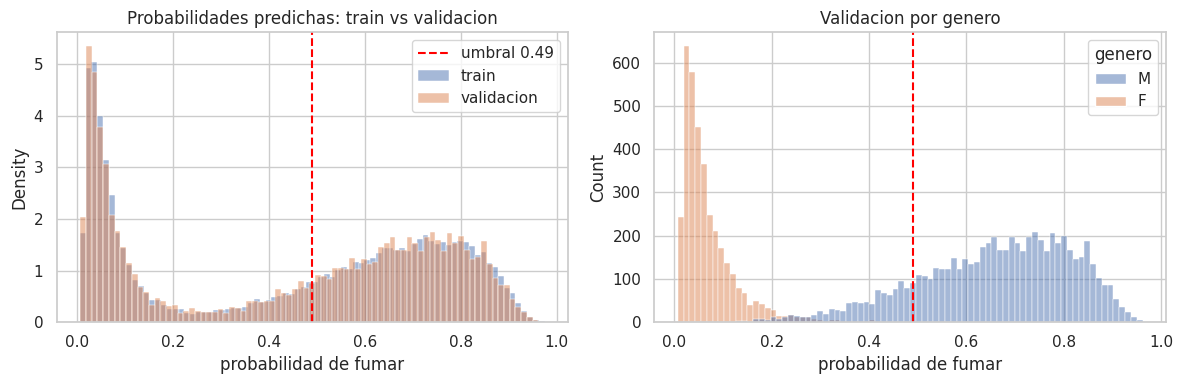

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(proba_train, bins=80, stat="density", label="train", alpha=0.5, ax=axes[0])
sns.histplot(proba_valid, bins=80, stat="density", label="validacion", alpha=0.5, ax=axes[0])
axes[0].set_title("Probabilidades predichas: train vs validacion")

genero = valid["gender"].map({0: "F", 1: "M"}).rename("genero")
sns.histplot(x=proba_valid, hue=genero, bins=80, ax=axes[1])
axes[1].set_title("Validacion por genero")

for ax in axes:
    ax.axvline(UMBRAL, color="red", ls="--", label=f"umbral {UMBRAL}")
    ax.set_xlabel("probabilidad de fumar")
axes[0].legend()
plt.tight_layout(); plt.show()

- **Train y validación se superponen:** misma mediana (0,536) y la misma proporción de probabilidades extremas (~17%). El modelo no está más seguro en train que en personas nuevas: otra señal de que **no sobreajusta**.
- **Las dos montañas son el género.** El 96% de las mujeres queda por debajo de 0,2 y casi ningún hombre. El modelo separa primero por sexo, que es la señal más fuerte.
- **El umbral (0,49) corta dentro de la montaña de los hombres.** Entre los hombres, fumadores (mediana 0,73) y no fumadores (0,61) se superponen mucho, y el 75% de los no fumadores queda por encima del umbral. De ahí salen casi todas las falsas alarmas de la sección 4.

## 3. ¿Qué tan preciso es el F1? Intervalo de confianza

Con **bootstrap** se remuestrean las filas de validación 1.000 veces y se recalcula el F1 cada vez. El rango entre los percentiles 2,5 y 97,5 da un intervalo de confianza del 95%.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
y_v = y_valid.to_numpy()
pred_v = valid_pred_best.astype(bool)

f1_boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_v), len(y_v))
    f1_boot.append(f1_score(y_v[i], pred_v[i]))

ic_inf, ic_sup = np.percentile(f1_boot, [2.5, 97.5])
print(f"F1 validacion: {f1_score(y_v, pred_v):.4f} | IC 95%: [{ic_inf:.4f}, {ic_sup:.4f}]")

F1 validacion: 0.7153 | IC 95%: [0.7050, 0.7265]


El F1 está entre ~0,705 y ~0,727 con 95% de confianza. La estimación de la CV (0,718) cae dentro del intervalo.

## 4. Matriz de confusión

Fumadores detectados (TP): 3240 de 3652 -> recall 0.887
Fumadores no detectados (FN): 412
Falsas alarmas (FP): 2167 -> de cada 100 marcados como fumadores, 60 lo son


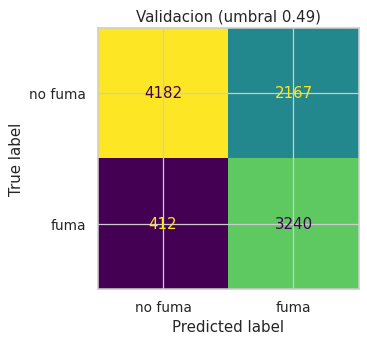

In [8]:
cm = confusion_matrix(y_valid, pred_v)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["no fuma", "fuma"]).plot(ax=ax, colorbar=False, values_format="d")
ax.set_title(f"Validacion (umbral {UMBRAL})")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Fumadores detectados (TP): {tp} de {tp + fn} -> recall {tp / (tp + fn):.3f}")
print(f"Fumadores no detectados (FN): {fn}")
print(f"Falsas alarmas (FP): {fp} -> de cada 100 marcados como fumadores, {100 * tp / (tp + fp):.0f} lo son")

- El modelo detecta ~89 de cada 100 fumadores (recall alto) y se le escapan 412.
- El costo es la precisión: de cada 100 personas que marca como fumadoras, 60 lo son. Las falsas alarmas son, en su mayoría, hombres no fumadores (ver sección 8).
- Maximizar el F1 lleva a este punto: al modelo le conviene marcar de más, porque perder un fumador le cuesta más F1 que una falsa alarma.

## 5. Curvas ROC y Precision-Recall

Miden cómo **ordena** el modelo a las personas por probabilidad, sin depender del umbral.

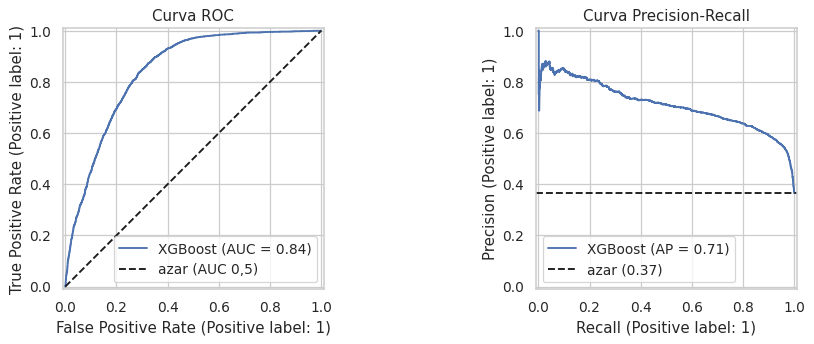

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_valid, proba_valid, name=NOMBRE, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="azar (AUC 0,5)")
axes[0].set_title("Curva ROC"); axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_valid, proba_valid, name=NOMBRE, ax=axes[1])
axes[1].axhline(y_valid.mean(), color="k", ls="--", label=f"azar ({y_valid.mean():.2f})")
axes[1].set_title("Curva Precision-Recall"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

- **ROC-AUC = 0,843:** buena separación (rango 0,8-0,9). Si se toma un fumador y un no fumador al azar, en el 84% de los casos el modelo le da más probabilidad al fumador.
- **PR-AUC = 0,71**, contra 0,37 de un modelo al azar.

## 6. ¿El umbral elegido era bueno?

Se recorre el F1 en validación para distintos umbrales, **solo como diagnóstico**: el umbral no se cambia, porque elegirlo acá sería usar validación para decidir y el resultado quedaría optimista.

F1 con el umbral elegido (0.49): 0.7153
Maximo posible en validacion: 0.7162 (umbral 0.51)


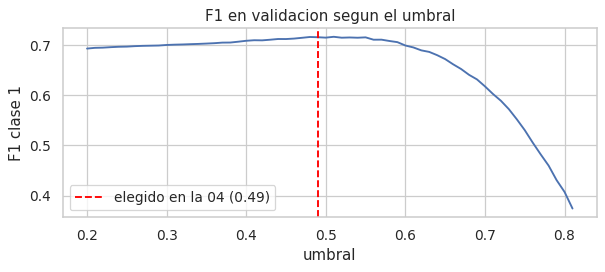

In [10]:
umbrales = np.round(np.arange(0.20, 0.81, 0.01), 2)
f1_por_umbral = pd.Series([f1_score(y_valid, proba_valid >= u) for u in umbrales], index=umbrales)

fig, ax = plt.subplots(figsize=(7, 3.2))
f1_por_umbral.plot(ax=ax)
ax.axvline(UMBRAL, color="red", ls="--", label=f"elegido en la 04 ({UMBRAL})")
ax.set_xlabel("umbral"); ax.set_ylabel("F1 clase 1"); ax.set_title("F1 en validacion segun el umbral"); ax.legend()
plt.tight_layout(); plt.show()

print(f"F1 con el umbral elegido ({UMBRAL}): {f1_por_umbral[UMBRAL]:.4f}")
print(f"Maximo posible en validacion: {f1_por_umbral.max():.4f} (umbral {f1_por_umbral.idxmax()})")

El máximo en validación está en 0,51 y supera al umbral elegido por apenas 0,001. El umbral elegido sin mirar validación quedó prácticamente en el óptimo: la elección fue robusta.

## 7. Importancia de las variables

Dos medidas:
- **Importancia por permutación (en validación):** se desordena una columna y se mide cuánto cae el F1. Si cae mucho, el modelo depende de esa variable. Se mide sobre datos no vistos.
- **Importancia interna de XGBoost (*gain*):** cuánto mejora el modelo, en promedio, cada corte que usa esa variable. Se calcula en train.

In [11]:
%%time
perm = permutation_importance(best_model, valid[FEATURES], y_valid, scoring="f1", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importancia = pd.DataFrame({
    "caida F1 (permutacion)": perm.importances_mean,
    "desvio": perm.importances_std,
    "gain (modelo)": best_model.feature_importances_,
}, index=FEATURES).sort_values("caida F1 (permutacion)", ascending=False)
importancia.head(12).round(4)

Wall time: 4.6 s


,caida F1 (permutacion),desvio,gain (modelo)
gender,0.1981,0.0024,0.6830
gtp,0.0445,0.0028,0.0277
age,0.0136,0.0022,0.0167
triglyceride,0.0103,0.0023,0.0145
alt,0.0065,0.0012,0.0102
tartar,0.0045,0.0010,0.0175
height_cm,0.0042,0.0014,0.0677
hemoglobin,0.0037,0.0016,0.0300
serum_creatinine,0.0027,0.0004,0.0151
dental_caries,0.0020,0.0009,0.0159


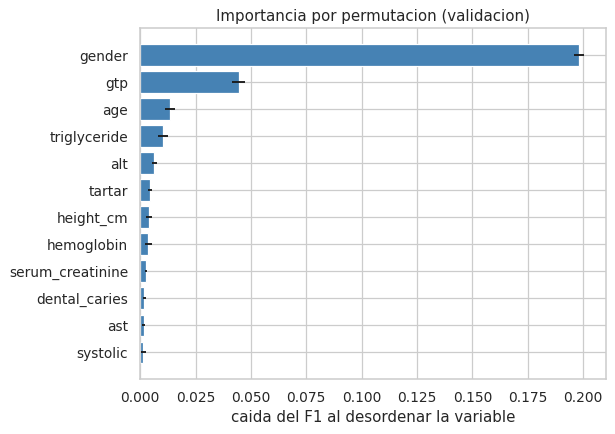

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
top = importancia.head(12).iloc[::-1]
ax.barh(top.index, top["caida F1 (permutacion)"], xerr=top["desvio"], color="steelblue")
ax.set_xlabel("caida del F1 al desordenar la variable"); ax.set_title("Importancia por permutacion (validacion)")
plt.tight_layout(); plt.show()

- **`gender` es por lejos la más importante:** desordenarla baja el F1 ~0,20. Es la señal más fuerte del dataset (55% de fumadores en hombres vs 4% en mujeres).
- Le sigue **`gtp`** (enzima hepática) y, bastante más abajo, edad, triglicéridos y ALT.
- **`height_cm` y `hemoglobin`** tienen *gain* alto pero importancia por permutación baja. Como reflejan el sexo, si se desordenan el modelo obtiene esa información de `gender`: son **redundantes** con `gender`, no señales propias.

## 8. Rendimiento por género

In [13]:
por_genero = []
for g, nombre in [(1, "hombres"), (0, "mujeres")]:
    m = (valid["gender"] == g).to_numpy()
    por_genero.append({
        "genero": nombre, "personas": int(m.sum()), "fumadores reales": int(y_v[m].sum()),
        "predichos fumadores": int(pred_v[m].sum()),
        "precision": precision_score(y_v[m], pred_v[m], zero_division=0),
        "recall": recall_score(y_v[m], pred_v[m]), "F1": f1_score(y_v[m], pred_v[m]),
    })
pd.DataFrame(por_genero).set_index("genero").round(3)

,personas,fumadores reales,predichos fumadores,precision,recall,F1
genero,,,,,,
hombres,6374,3494,5403,0.599,0.926,0.728
mujeres,3627,158,4,0.750,0.019,0.037


En **hombres** el modelo detecta al 93% de los fumadores (F1 0,73). En **mujeres** marca como fumadoras a solo 4 personas y detecta 3 de las 158 fumadoras. Con ~4% de fumadoras entre las mujeres, al modelo le conviene clasificarlas a todas como no fumadoras. Es la principal **limitación** del modelo.

## 9. ¿Qué esperar en el archivo de entrega?

En la 03 se vio que **todas** las filas del archivo de entrega son copia de una persona etiquetada (registros duplicados con el mismo `smoking`). O sea que la entrega **no** son personas nuevas: el modelo ya vio a la mayoría al entrenar.

Para estimar el F1 esperado, se compara la predicción de cada fila de la entrega con el `smoking` de **su copia etiquetada**. Esa etiqueta se usa **solo para medir**: las predicciones de la 06 salen únicamente del modelo.

In [14]:
entrega =pd.read_csv(PROCESSED_DIR / "entrega.csv")
etiquetados = pd.concat([train.assign(origen="train"), valid.assign(origen="validacion")], ignore_index=True)

# Grupo comun para etiquetados + entrega: las copias de una persona comparten numero
combinado = pd.concat([etiquetados[FEATURES], entrega[FEATURES]], ignore_index=True)
g = utils.grupos_duplicados(combinado, FEATURES)
etiquetados["grupo"], entrega["grupo"] = g[:len(etiquetados)], g[len(etiquetados):]

copia = etiquetados.drop_duplicates("grupo").set_index("grupo")
entrega["smoking de la copia"] = entrega["grupo"].map(copia[TARGET])
entrega["copia en"] = entrega["grupo"].map(copia["origen"])
print("Filas de la entrega con copia etiquetada:", f"{entrega['smoking de la copia'].notna().mean():.0%}")
print(entrega["copia en"].value_counts(normalize=True).round(3).to_frame("% de la entrega"))

Filas de la entrega con copia etiquetada: 100%
            % de la entrega
copia en                   
train                 0.797
validacion            0.203


In [15]:
pred_entrega = best_model.predict_proba(entrega[FEATURES])[:, 1] >= UMBRAL
estimacion = {}
for origen in ["train", "validacion"]:
    m = (entrega["copia en"] == origen).to_numpy()
    estimacion[f"copia en {origen}"] = {"filas": int(m.sum()),
                                        "F1": f1_score(entrega.loc[m, "smoking de la copia"], pred_entrega[m])}
estimacion["total entrega"] = {"filas": len(entrega), "F1": f1_score(entrega["smoking de la copia"], pred_entrega)}
pd.DataFrame(estimacion).T.round(4)

,filas,F1
copia en train,4538.0,0.7407
copia en validacion,1154.0,0.7207
total entrega,5692.0,0.7365


- El 80% de las filas de la entrega es copia de alguien de train, y el 20% de alguien de validación.
- **F1 estimado en la entrega: ≈ 0,74.** Es apenas mayor que en validación (0,715), porque el modelo casi no memoriza: le va un poco mejor con las personas que vio (0,741) que con las que no (0,721).
- Un modelo que memoriza sacaría mucho más en la entrega, pero rendiría peor con personas nuevas. Se eligió el que generaliza.

## 10. Guardado de métricas

In [16]:
resumen = {
    "modelo": NOMBRE,
    "config": config["config"],
    "umbral": UMBRAL,
    "f1_cv": config["f1_cv"],
    "f1_train": round(float(comparacion.loc["train (visto)", "F1"]), 4),
    "f1_validacion": round(float(f1_score(y_v, pred_v)), 4),
    "f1_validacion_ic95": [round(float(ic_inf), 4), round(float(ic_sup), 4)],
    "roc_auc_validacion": round(float(roc_auc_score(y_valid, proba_valid)), 4),
    "f1_entrega_estimado": round(float(estimacion["total entrega"]["F1"]), 4),
}
(MODELS_DIR / "metricas_validacion.json").write_text(json.dumps(resumen, indent=2))
resumen

{'modelo': 'XGBoost', 'config': '{"colsample_bytree": 0.7554, "gamma": 0.8348, "learning_rate": 0.0195, "max_depth": 4, "min_child_weight": 10, "n_estimators": 600, "reg_lambda": 0.3078, "subsample": 0.6673}', 'umbral': 0.49, 'f1_cv': 0.7179, 'f1_train': 0.7324, 'f1_validacion': 0.7153, 'f1_validacion_ic95': [0.705, 0.7265], 'roc_auc_validacion': 0.8431, 'f1_entrega_estimado': 0.7365}

## 11. Conclusiones

| Pregunta | Respuesta |
|---|---|
| F1 de la clase 1 en personas nuevas | **0,715** (IC 95% ≈ 0,705-0,727) |
| ¿Coincide con la CV de la 04? | Sí: la CV estimó 0,718, dentro del intervalo |
| ¿Sobreajusta? | **No:** train 0,732 vs validación 0,715 (brecha 0,017) |
| Separación de clases | ROC-AUC 0,843 (buena), PR-AUC 0,71 (azar: 0,37) |
| Errores | Detecta 89% de los fumadores. Precisión 60%: marca de más, sobre todo hombres no fumadores |
| Umbral | El de la 04 (0,49) queda a 0,001 del óptimo en validación |
| Variables clave | `gender` y `gtp`. Altura y hemoglobina son redundantes con `gender` |
| Limitación | Casi no detecta mujeres fumadoras (3 de 158 en validación) |
| Entrega | Son copias de personas etiquetadas. F1 estimado ≈ 0,74 |

El modelo queda validado sin cambios y se usa tal cual en la notebook 06.